# 5 · EDA - Exploratory Data Analysis

## 0. Chuẩn bị dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_cleaned = pd.read_csv("../data/cleaned/olist_clean.csv")

print("Shape cleaned:", file_cleaned.shape)


Shape cleaned: (108937, 27)


### Nhận xét

- Đọc thành công bảng dữ liệu sau Cleaning.
- Dữ liệu gồm **108.937 dòng và 27 cột**, khớp số liệu Cleaning của nhóm.
- Sử dụng bảng này làm đầu vào chính cho EDA.

**Kết luận:** Dữ liệu đã được tải thành công. Tiếp tục kiểm tra cấu trúc và chất lượng trước khi phân tích.

## 1. Xác minh dữ liệu sau Cleaning ##

### 1.1. Kiểm tra cấu trúc dữ liệu

**Mục tiêu:** Xác định tên cột và kiểu dữ liệu của bảng sau Cleaning.

In [2]:
df1_1 = file_cleaned.dtypes.reset_index()
df1_1 = df1_1.rename(columns={
    "index" : "Name column",
    0 : "Data type"
}) 
display(df1_1)


,Name column,Data type
0,order_id,object
1,order_item_id,int64
2,product_id,object
3,seller_id,object
4,price,float64
5,freight_value,float64
6,customer_id,object
7,order_purchase_timestamp,object
8,weight_g,float64
9,length_cm,float64


**Nhận xét:**
- Dữ liệu gồm 108.937 dòng và 27 cột.
- Mỗi dòng dự kiến đại diện cho một item trong đơn hàng.
- `freight_value` là biến mục tiêu cần dự đoán.
- Các cột còn lại cung cấp thông tin về sản phẩm, đơn hàng, thời gian và vị trí vận chuyển.
- `order_purchase_timestamp` cần được chuyển sang datetime khi phân tích thời gian.
- Các cột định danh và mã bưu chính không phải đại lượng số để phân tích trực tiếp.

**Kết luận:** Đã xác định cấu trúc và vai trò ban đầu của 27 cột. Tiếp tục kiểm tra tính toàn vẹn của dữ liệu.

### 1.2. Kiểm tra dữ liệu thiếu và trùng lặp

**Mục tiêu:** Kiểm tra dữ liệu sau Cleaning còn giá trị thiếu hoặc trùng khóa hay không.

**Nội dung kiểm tra:**
1. Missing Values: Đếm số giá trị thiếu ở từng cột.
2. Duplicate Keys: Kiểm tra trùng cặp khóa `(order_id, order_item_id)`.
3. Key Nulls: Kiểm tra các cột khóa có giá trị thiếu hay không.

In [3]:
miss_values = file_cleaned.isnull().sum().sum()
duplicated_keys = file_cleaned.duplicated(subset=["order_id","order_item_id"]).sum()
key_nulls = file_cleaned[["order_id","order_item_id"]].isnull().any(axis=1).sum()
df1_2 = pd.DataFrame({
    "Check" : ["miss_values", "duplicated_keys", "key_nulls"],
    "Value" : [miss_values,duplicated_keys,key_nulls]
})
display(df1_2)


,Check,Value
0,miss_values,0
1,duplicated_keys,0
2,key_nulls,0


**Kết quả:**
- Tổng giá trị thiếu: 0.
- Trùng khóa `(order_id, order_item_id)`: 0.
- Giá trị thiếu trong khóa: 0.

**Kết luận:** Bảng sau Cleaning không còn giá trị thiếu và không phát hiện trùng khóa. Dữ liệu đạt yêu cầu của hai phép kiểm tra này, nhưng chưa đủ để khẳng định mọi giá trị đều hợp lệ.

### 1.3. Kiểm tra tính hợp lệ của dữ liệu

**Mục tiêu:** Xác minh các cột số sau Cleaning có vi phạm những quy tắc giá trị cơ bản hay không.

**Quy tắc kiểm tra:**
- `freight_value`, `distance_km`: Không được âm.
- `price`, `weight_g`, `length_cm`, `height_cm`, `width_cm`, `volume_cm3`: Phải lớn hơn 0.

Các trường hợp `freight_value = 0` đã được xử lý trong Cleaning nên không điều tra lại ở đây.

In [4]:
freight_value_check = (file_cleaned["freight_value"] < 0).sum()
price_check = (file_cleaned["price"] <= 0).sum()
weight_g_check = (file_cleaned["weight_g"] <= 0).sum()
length_cm_check = (file_cleaned["length_cm"] <= 0).sum()
height_cm_check = (file_cleaned["height_cm"] <= 0).sum()
width_cm_check = (file_cleaned["width_cm"] <= 0).sum()
distance_km_check = (file_cleaned["distance_km"] < 0).sum()
volume_cm3_check = (file_cleaned["volume_cm3"] <= 0).sum()
df1_3 = pd.DataFrame({
    "Check" : ["freight_value_check","price_check","weight_g_check","length_cm_check","height_cm_check","width_cm_check","distance_km_check","volume_cm3_check"],
    "Value" : [freight_value_check,price_check,weight_g_check,length_cm_check,height_cm_check,width_cm_check,distance_km_check,volume_cm3_check]
})
display(df1_3)

,Check,Value
0,freight_value_check,0
1,price_check,0
2,weight_g_check,0
3,length_cm_check,0
4,height_cm_check,0
5,width_cm_check,0
6,distance_km_check,0
7,volume_cm3_check,0


**Nhận xét:** Các cột được kiểm tra đáp ứng quy tắc giá trị cơ bản sau Cleaning.

**Kết luận:** Không phát hiện giá trị âm hoặc không dương trái quy tắc trong 8 cột.

### 1.4. Chuyển đổi kiểu dữ liệu

**Mục tiêu:** Đảm bảo các cột có kiểu dữ liệu phù hợp trước khi thực hiện EDA.

**Kiểm tra:**
- `order_purchase_timestamp`: Chuyển từ `str` sang `datetime` để phân tích thời gian.
- `month`: Giữ dạng chuỗi để phân nhóm theo tháng.
- `c_zip`, `s_zip`: Là mã bưu chính, không sử dụng như biến số liên tục.
- Các cột số còn lại: Giữ nguyên kiểu dữ liệu hiện tại nếu phù hợp.

In [5]:
file_cleaned["order_purchase_timestamp"] = pd.to_datetime(file_cleaned["order_purchase_timestamp"],errors="coerce")
print("Dtypes column:",file_cleaned["order_purchase_timestamp"].dtypes)
print("Null Value:",file_cleaned["order_purchase_timestamp"].isnull().sum())

Dtypes column: datetime64[ns]
Null Value: 0



**Kết quả:**
- Chuyển thành công `order_purchase_timestamp` từ chuỗi sang `datetime64[us]`.
- Không phát sinh giá trị thiếu (`NaT = 0`).
- Các cột khác được giữ nguyên kiểu dữ liệu.

**Kết luận:** Cột thời gian đã sẵn sàng cho EDA. Việc chuyển đổi không làm phát sinh giá trị thiếu và không thay đổi dữ liệu gốc trên ổ đĩa.


## 2. Phân tích phí vận chuyển (freight_value) ##

### 2.1. Thống kê mô tả phí vận chuyển

**Mục tiêu:** Xác định mức phí điển hình, sự phân bố và các giá trị bất thường của `freight_value`.

**Phương pháp:**
- Thống kê mô tả: `describe()`.
- Histogram: Quan sát phân phối phí.
- Boxplot và IQR: Phát hiện các giá trị nằm ngoài khoảng thông thường.

In [6]:
freight_value_2_1 = file_cleaned["freight_value"].describe().round(3).reset_index()
display(freight_value_2_1)

,index,freight_value
0,count,108937.000
1,mean,20.012
2,std,15.701
3,min,0.010
4,25%,13.080
5,50%,16.280
6,75%,21.150
7,max,409.680


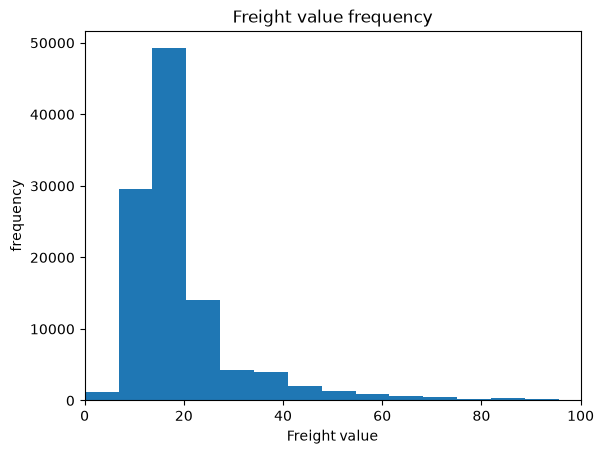

In [7]:
plt.hist(file_cleaned["freight_value"], bins=60)
plt.title("Freight value frequency")
plt.xlim(0,100)
plt.xlabel("Freight value")
plt.ylabel("frequency")
plt.show()

Lower fence: 0.975
Upper fence: 33.255
Below lower fence: 133
Above upper fence: 11216
Total outliers: 11349
Tỷ lệ: 10.42 %


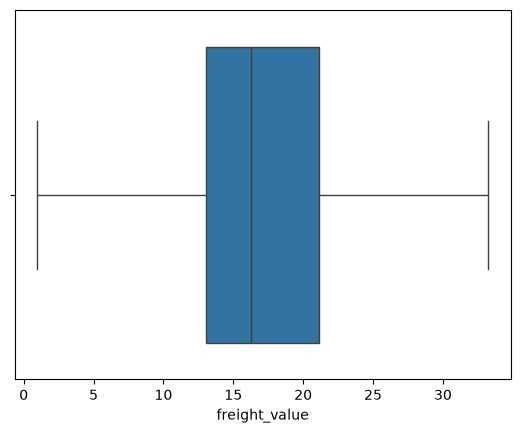

In [8]:
q1 = freight_value_2_1.loc[4, "freight_value"]
q3 = freight_value_2_1.loc[6, "freight_value"]
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

below_lower = file_cleaned["freight_value"] < lower
above_upper = file_cleaned["freight_value"] > upper
outliers = below_lower | above_upper

print("Lower fence:", round(lower, 3))
print("Upper fence:", round(upper, 3))
print("Below lower fence:", below_lower.sum())
print("Above upper fence:", above_upper.sum())
print("Total outliers:", outliers.sum())
print("Tỷ lệ:", round(outliers.mean() * 100, 2), "%")

sns.boxplot(data=file_cleaned, x="freight_value", showfliers=False)
plt.show()


**Kết quả:** mean 20,01 BRL lớn hơn median 16,28 BRL; 50% item nằm từ 13,08 đến 21,15 BRL. Phân phối lệch phải và có đuôi dài tới 409,68 BRL. Histogram giới hạn trục ở 100 BRL chỉ để phần chính dễ quan sát, không loại dữ liệu; boxplot dùng `showfliers=False` chỉ ẩn điểm cực đoan trên hình.

Với rào dưới 0,975 và rào trên 33,255 BRL, có 133 item dưới rào dưới và 11.216 item trên rào trên, tổng 11.349 item (10,42%). Cleaning chỉ báo cáo 11.216 item vượt rào trên, còn EDA báo cáo cả hai phía nên hai con số không mâu thuẫn. Đây là điểm cực đoan thống kê, không phải bằng chứng lỗi, nên vẫn được giữ; RMSE và error analysis sẽ phản ánh khó khăn ở đuôi cao.



### 2.2. Phân tích phí vận chuyển theo thời gian

**Mục tiêu:** Kiểm tra sự thay đổi của phí vận chuyển qua các tháng.

**Phương pháp:**
- `groupby()`, `agg()`: Thống kê số item, phí trung bình và trung vị theo tháng.
- Lineplot: Quan sát xu hướng phí vận chuyển theo thời gian.

**Câu hỏi:** Phí vận chuyển có thay đổi đáng kể giữa các tháng không?


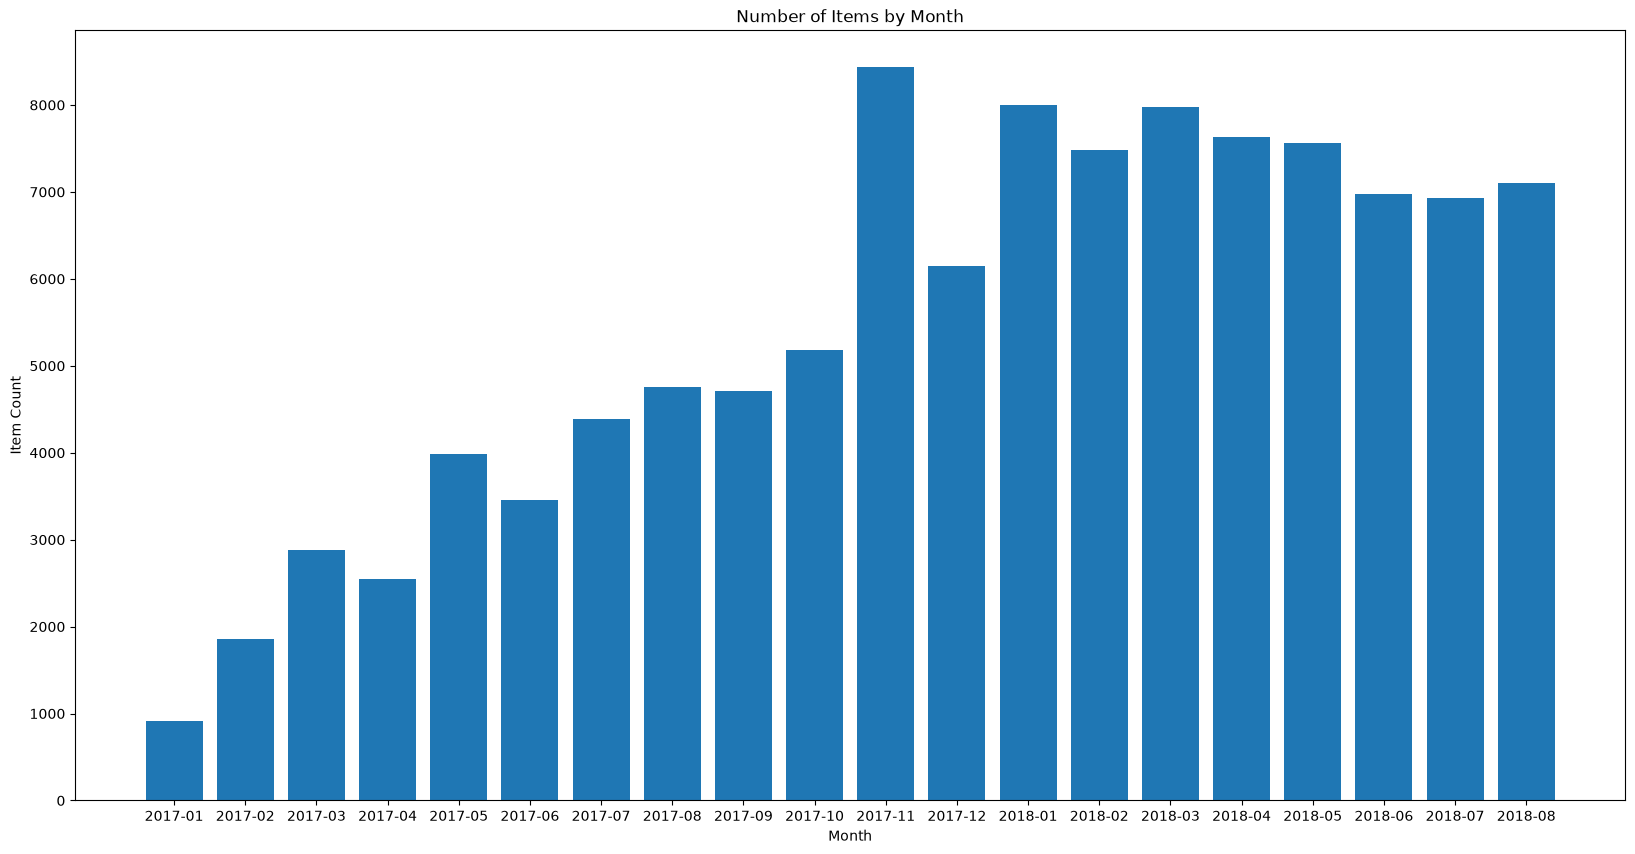

In [9]:
df2_2 = file_cleaned.groupby("month")["freight_value"].count().reset_index()
df2_2 = df2_2.sort_values(by="month", ascending=True)
plt.figure(figsize=(20, 10))
plt.bar(df2_2["month"], df2_2["freight_value"])
plt.xlabel("Month")
plt.ylabel("Item Count")
plt.title("Number of Items by Month")
plt.show()

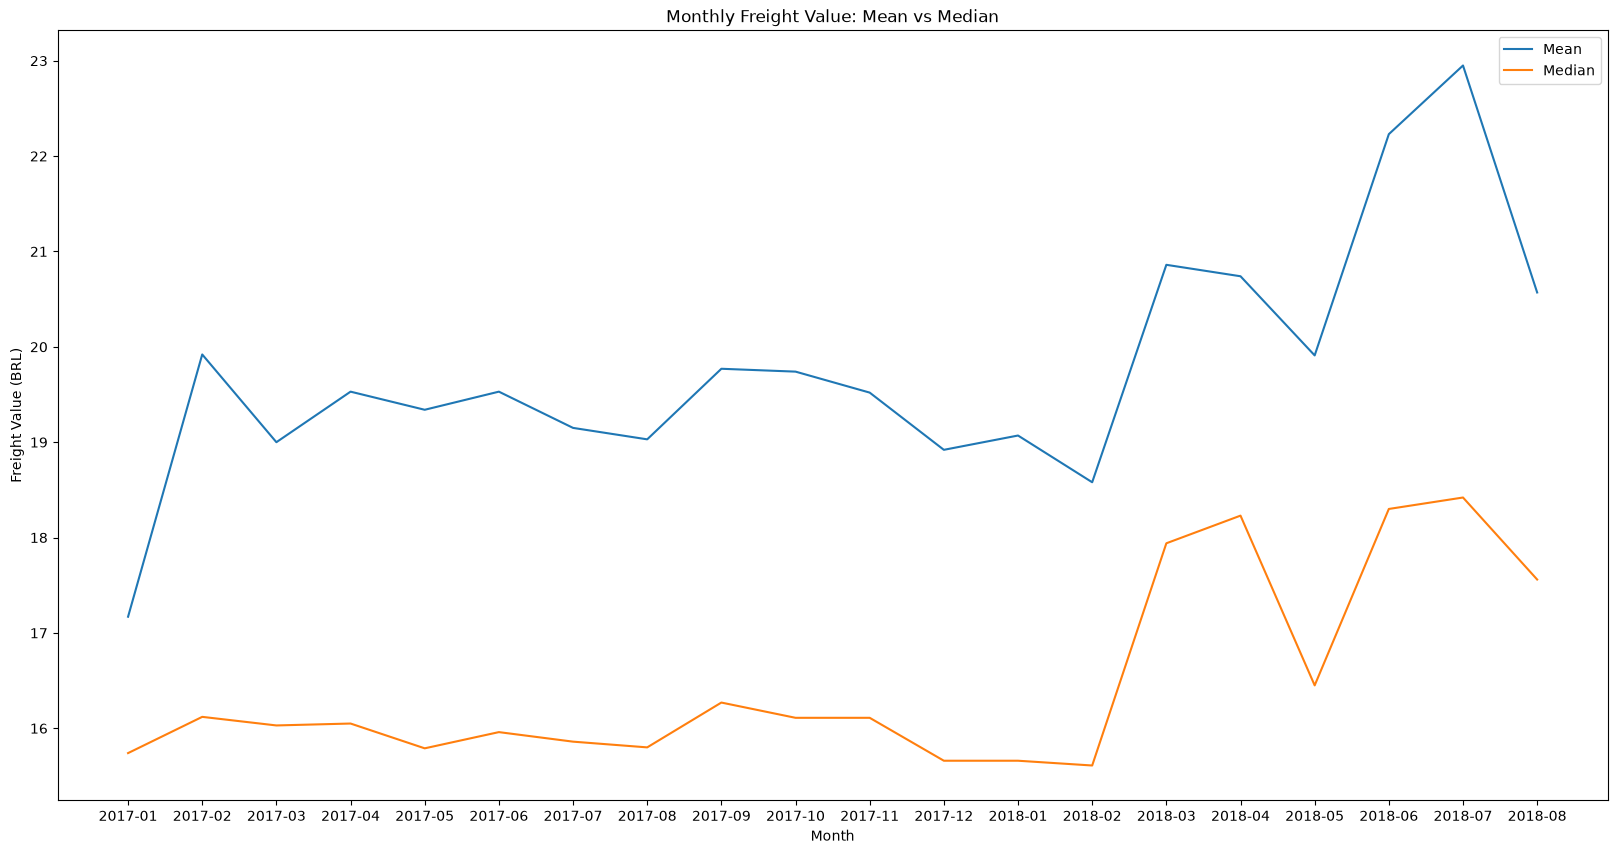

In [10]:
df2_2 = file_cleaned.groupby("month").agg(Mean = ("freight_value","mean"), Median=("freight_value","median")).round(2).reset_index()
plt.figure(figsize=(20,10))
sns.lineplot(data=df2_2, x="month", y="Mean", label="Mean")
sns.lineplot(data=df2_2, x="month", y="Median", label="Median")
plt.title("Monthly Freight Value: Mean vs Median")
plt.xlabel("Month")
plt.ylabel("Freight Value (BRL)")
plt.show()

Phí trung vị tương đối ổn định quanh 15–16 BRL trong phần lớn năm 2017 và đầu 2018, sau đó cao hơn ở một số tháng, rõ nhất vào 06–07/2018; tháng 07/2018 có mean 22,95 và median 18,42 BRL. Mean luôn cao hơn median cho thấy đuôi phải tồn tại qua các tháng, không chỉ ở một thời điểm riêng lẻ.

Biểu đồ chưa cho biết sự thay đổi đến từ biểu phí, mùa vụ hay cơ cấu sản phẩm/khoảng cách, vì các yếu tố đó chưa được giữ cố định. Dữ liệu chỉ có 20 tháng và những tháng đầu có ít item hơn, nên không đủ để suy ra một quy luật mùa vụ lặp lại. Vì phân phối có thể thay đổi theo thời gian, Modeling cần huấn luyện trên giai đoạn trước, chọn model bằng tháng 07/2018 và chỉ đánh giá cuối trên tháng 08/2018 thay vì trộn ngẫu nhiên toàn bộ lịch sử.


## 3. Phân tích các yếu tố liên quan đến phí vận chuyển ##

**Mục tiêu:** Tìm hiểu vì sao các item có mức freight_value khác nhau, từ đó đề xuất những đặc trưng đáng thử trong Modeling.


### 3.1. Cân nặng và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa cân nặng sản phẩm (`weight_g`) và phí vận chuyển (`freight_value`).

**Phương pháp:**
- Scatterplot: Quan sát xu hướng và độ phân tán.
- Pearson: Đánh giá mức độ tương quan tuyến tính.


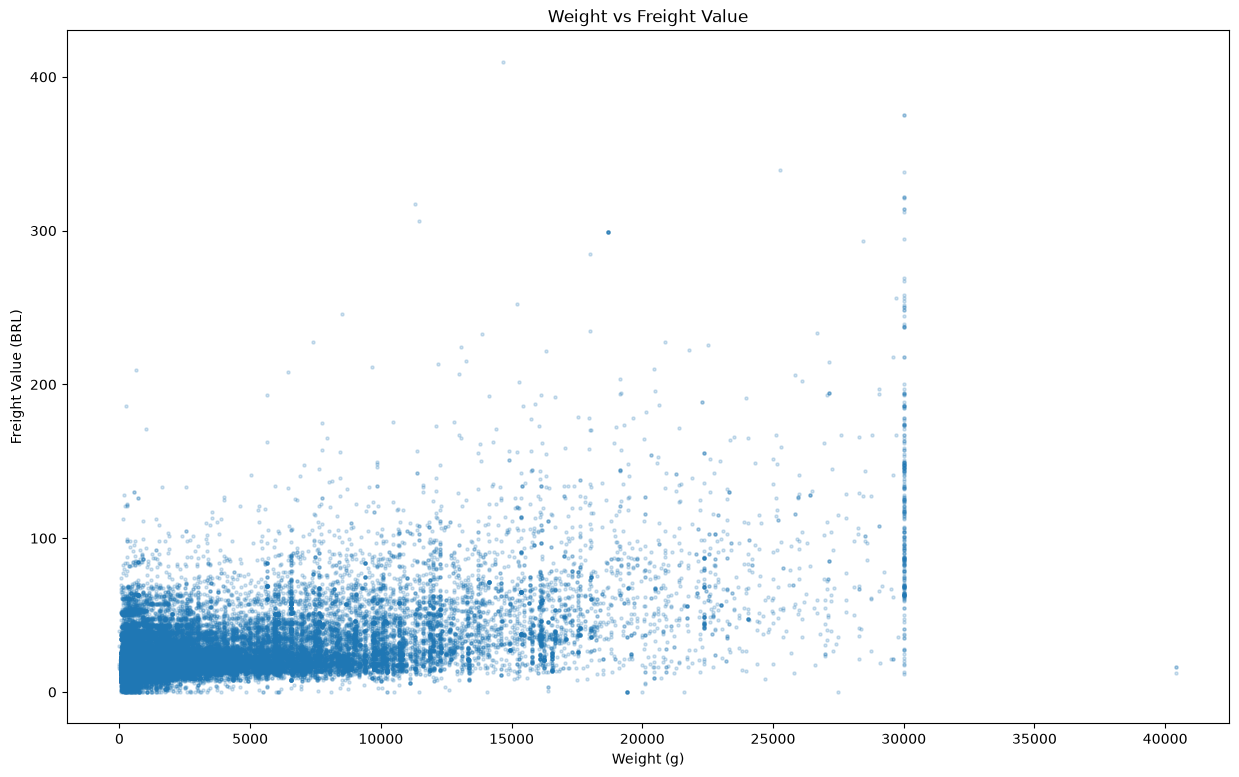

In [11]:
df3_1 = file_cleaned[["weight_g","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_1["weight_g"], df3_1["freight_value"], s=5, alpha=0.2)
plt.title("Weight vs Freight Value")
plt.xlabel("Weight (g)")
plt.ylabel("Freight Value (BRL)")
plt.show()

In [12]:
cor = df3_1[["weight_g","freight_value"]].corr(method="pearson")
display(cor.round(2))

,weight_g,freight_value
weight_g,1.00,0.61
freight_value,0.61,1.00


Cân nặng phản ánh trực tiếp một đặc điểm vật lý của sản phẩm. Scatterplot cho thấy freight thường tăng theo `weight_g`, nhưng độ phân tán cũng mở rộng ở hàng nặng: cùng cân nặng vẫn có nhiều mức phí và có các điểm phí rất cao. Pearson 0,61 xác nhận mối liên hệ tuyến tính dương tương đối rõ, song cụm 30.000 g và dạng phân tán cho thấy một đường thẳng không giải thích hết dữ liệu. Vì vậy cân nặng là thông tin hữu ích, nhưng cần kết hợp với thể tích, khoảng cách và đặc điểm khu vực; kết quả không chứng minh cân nặng là nguyên nhân duy nhất của phí.


### 3.2. Thể tích và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa thể tích sản phẩm (`volume_cm3`) và phí vận chuyển (`freight_value`).

**Phương pháp:**
- Scatterplot: Quan sát xu hướng giữa thể tích và phí.
- Pearson: Đánh giá mức độ tương quan tuyến tính.

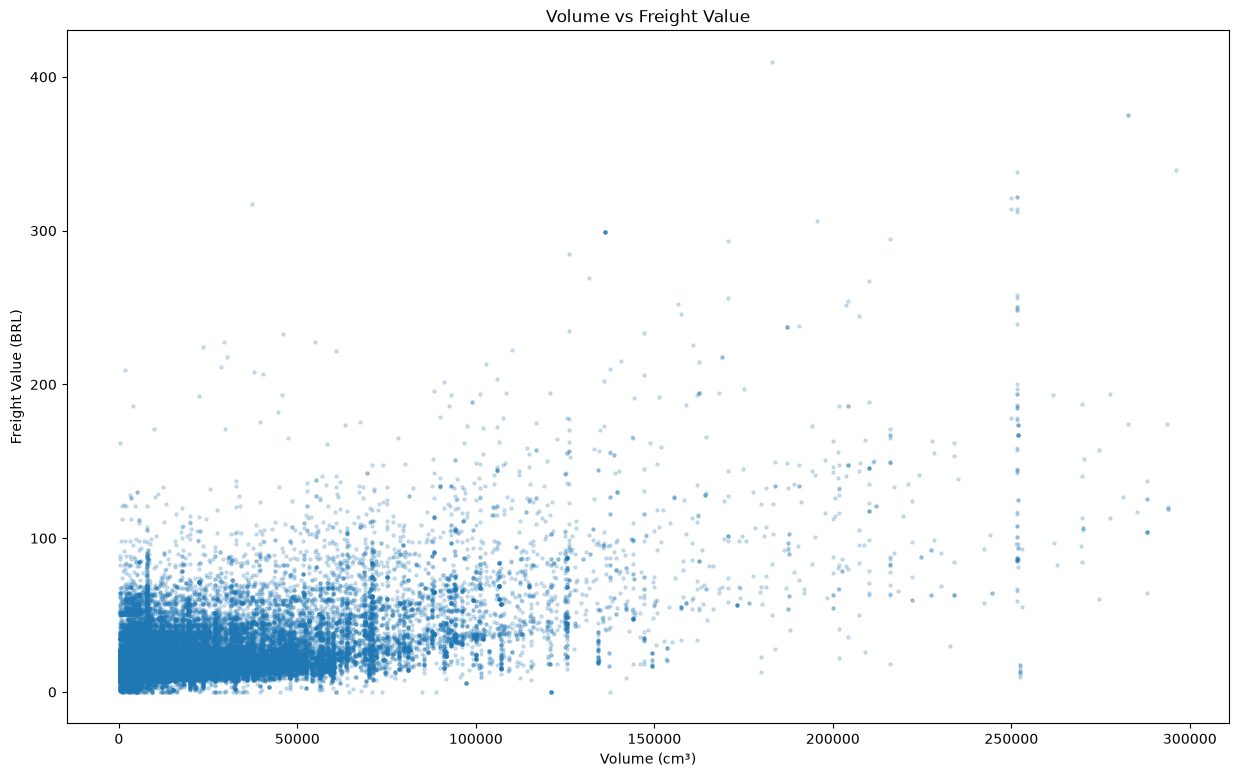

In [13]:
df3_2 = file_cleaned[["volume_cm3","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_2["volume_cm3"], df3_2["freight_value"], s=5, alpha=0.2)
plt.title("Volume vs Freight Value")
plt.xlabel("Volume (cm³)")
plt.ylabel("Freight Value (BRL)")
plt.show()

In [14]:
cor = df3_2[["volume_cm3","freight_value"]].corr(method="pearson")
display(cor.round(2))

,volume_cm3,freight_value
volume_cm3,1.00,0.58
freight_value,0.58,1.00


Thể tích đại diện mức độ cồng kềnh và có xu hướng đi cùng freight cao hơn, nhưng scatterplot vẫn chồng lấn mạnh; các item gần 250.000 cm³ tạo vùng cực đoan và quan hệ không hoàn toàn tuyến tính. Pearson 0,58 cho thấy tín hiệu tuyến tính đáng kể, đồng thời thấp hơn weight một chút. Vì volume tương quan 0,81 với weight, hai feature chứa thông tin chồng lặp nhưng không hoàn toàn giống nhau; EDA chưa đủ căn cứ để bỏ một feature trước khi đánh giá kết hợp trên validation.



### 3.3. Khoảng cách và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa khoảng cách vận chuyển (`distance_km`) và phí vận chuyển (`freight_value`).

**Phương pháp:**
- Scatterplot: Quan sát xu hướng và độ phân tán.
- Pearson: Đánh giá mức độ tương quan tuyến tính.

**Lưu ý:** `distance_km` là khoảng cách ước tính từ tọa độ, không nhất thiết phản ánh quãng đường vận chuyển thực tế.


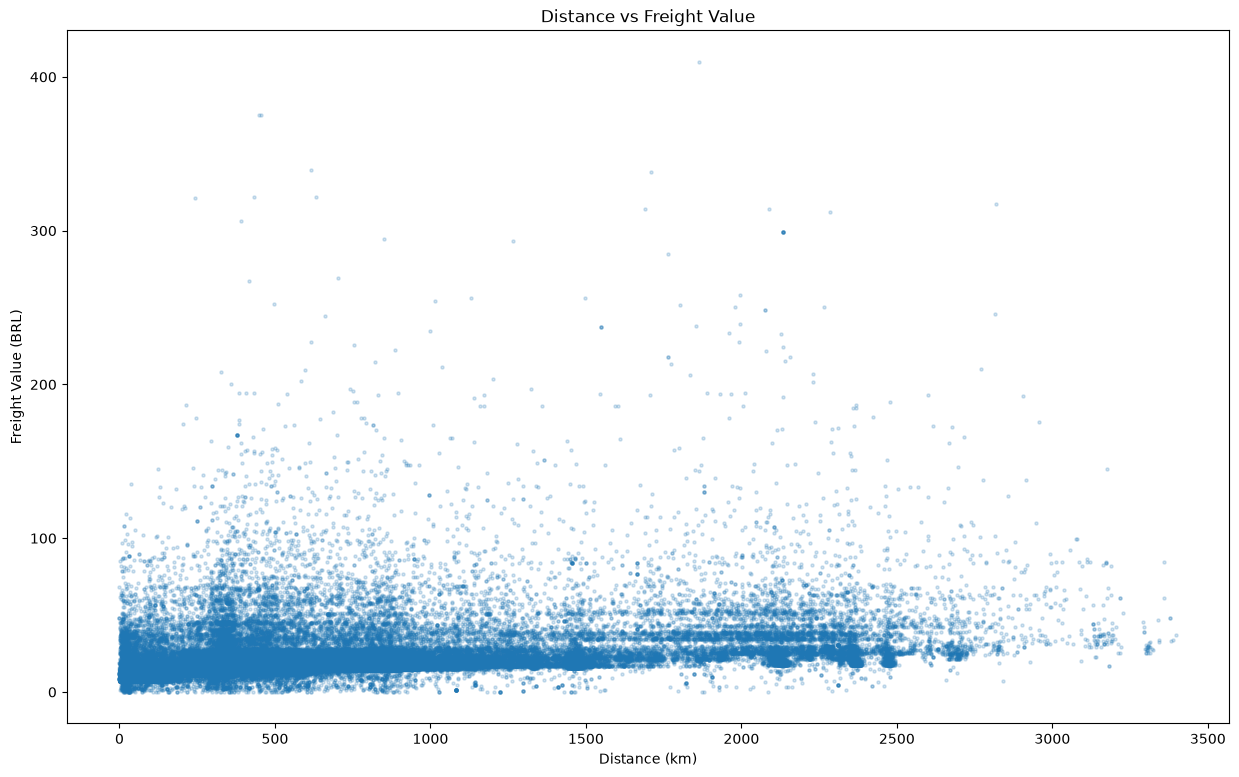

In [15]:
df3_3 = file_cleaned[["distance_km","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_3["distance_km"], df3_3["freight_value"], s=5, alpha=0.2)
plt.title("Distance vs Freight Value")
plt.xlabel("Distance (km)")
plt.ylabel("Freight Value (BRL)")
plt.show()

In [16]:
cor = df3_3[["distance_km","freight_value"]].corr(method="pearson")
display(cor.round(2))

,distance_km,freight_value
distance_km,1.00,0.39
freight_value,0.39,1.00


Khoảng cách phản ánh khác biệt địa lý giữa nơi gửi và nhận. Freight nhìn chung tăng khi `distance_km` lớn hơn, nhưng độ phân tán rất rộng và cùng một khoảng cách có nhiều mức phí, nên quan hệ chỉ tuyến tính một phần; Pearson 0,39 phù hợp với nhận xét này. Các tuyến xa có cả điểm phí rất cao lẫn mức thông thường, cho thấy khoảng cách không đủ để dự đoán một mình. Ngoài ra đây là Haversine giữa tọa độ ZIP đại diện, không phải quãng đường hoặc tuyến vận chuyển thực tế.



### 3.4. Giá sản phẩm và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa giá sản phẩm (`price`) và phí vận chuyển (`freight_value`).

**Phương pháp:**
- Scatterplot: Quan sát xu hướng và độ phân tán.
- Pearson: Đánh giá mức độ tương quan tuyến tính.


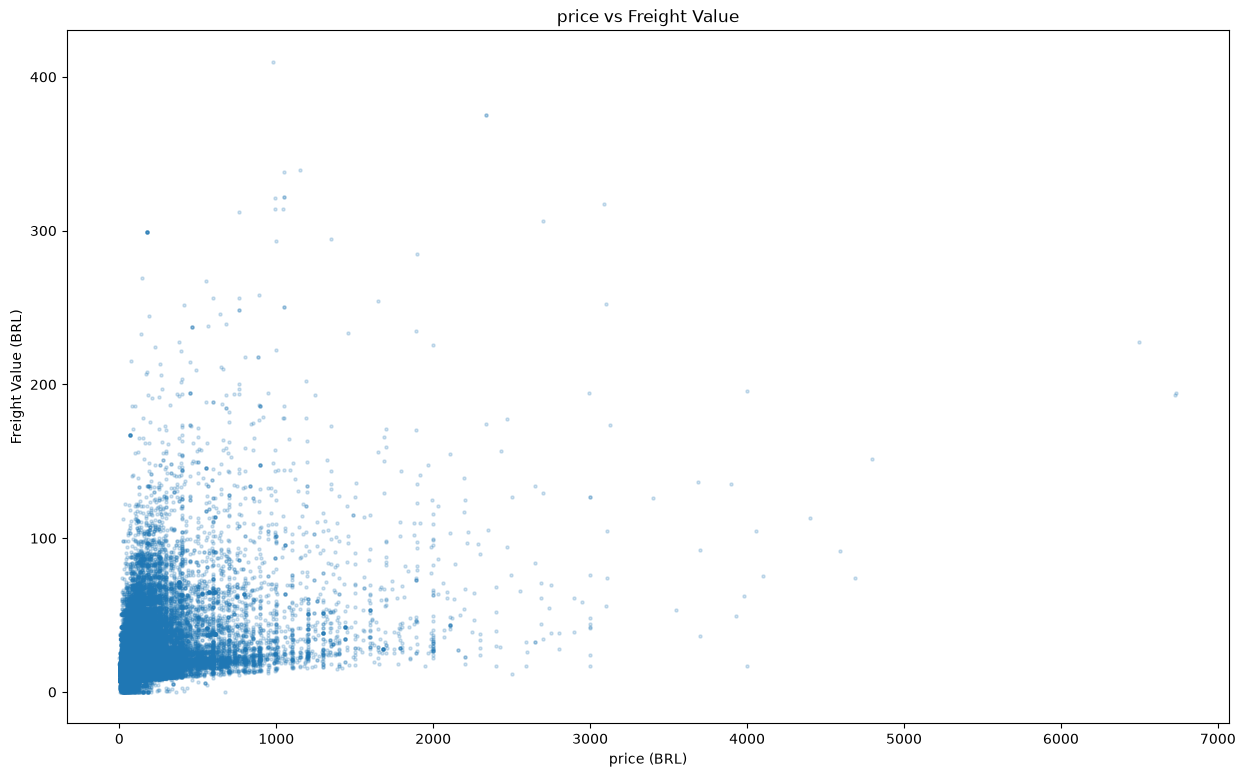

In [17]:
df3_4 = file_cleaned[["price","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_4["price"], df3_4["freight_value"], s=5, alpha=0.2)
plt.title("price vs Freight Value")
plt.xlabel("price (BRL)")
plt.ylabel("Freight Value (BRL)")
plt.show()

In [18]:
cor = df3_4[["price","freight_value"]].corr(method="pearson")
display(cor.round(2))

,price,freight_value
price,1.00,0.41
freight_value,0.41,1.00


Price có tương quan dương mức vừa với freight (0,41), nhưng scatterplot phân tán lớn và không tạo một quan hệ tuyến tính rõ trên toàn miền. Giá có thể đi cùng loại sản phẩm, kích thước hoặc những yếu tố chưa quan sát, nhưng biểu đồ này không tách được các khả năng đó và không chứng minh sản phẩm đắt gây phí cao. Vì price có sẵn tại checkout và bổ sung một khía cạnh khác đặc điểm vật lý, feature này được giữ để hai model đánh giá trong tổ hợp chung.



### 3.5. Khu vực và phí vận chuyển

**Mục tiêu:** So sánh phí vận chuyển giữa các item giao cùng bang (`same_state = 1`) và khác bang (`same_state = 0`).

**Phương pháp:**
- `groupby()` và `agg()`: So sánh số item, Mean và Median.
- Boxplot: Quan sát sự khác biệt về phân phối phí giữa hai nhóm.


In [19]:
df3_5 = file_cleaned.groupby('same_state')['freight_value'].describe()
df3_5 = df3_5[['count', '25%', '50%', '75%']].round(2)
display(df3_5)


,count,25%,50%,75%
same_state,,,,
0,69330.0,15.79,18.26,24.11
1,39607.0,8.80,12.03,14.06


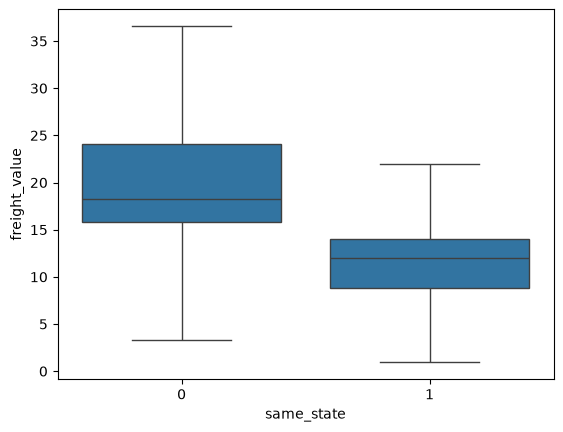

In [20]:
sns.boxplot(data=file_cleaned, x="same_state",y="freight_value", showfliers=False)
plt.show()

**Nhận xét:** khác bang có 69.330 item, median 18,26 BRL và IQR 15,79–24,11; cùng bang có 39.607 item, median 12,03 BRL và IQR 8,80–14,06. Hai IQR gần như tách nhau nhưng phân phối vẫn có chồng lấn; outlier chỉ bị ẩn trên boxplot, không bị xóa. `same_state` đáng thử nhưng tương quan -0,57 với `distance_km`, nên không diễn giải như tác động nhân quả riêng.



### 3.6. Số item trong đơn hàng và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa số lượng item trong đơn hàng (`order_n_items`) và phí vận chuyển trên mỗi item (`freight_value`).

**Phương pháp:**
- `groupby()` và `agg()`: Thống kê số item, Mean và Median theo quy mô đơn hàng.
- Boxplot: So sánh phân phối phí giữa các nhóm.


In [21]:
df3_6 = file_cleaned.groupby('order_n_items')['freight_value'].agg(
    Count='count', Mean='mean', Median='median'
)
df3_6['Q1'] = file_cleaned.groupby('order_n_items')['freight_value'].quantile(0.25)
df3_6['Q3'] = file_cleaned.groupby('order_n_items')['freight_value'].quantile(0.75)
display(df3_6.round(2))


,Count,Mean,Median,Q1,Q3
order_n_items,,,,,
1,85856,20.39,16.47,13.44,21.35
2,14595,18.60,15.65,12.35,19.94
3,3885,18.33,15.79,11.85,20.05
4,1956,18.58,16.11,12.69,20.57
5,950,18.29,15.10,10.00,21.35
6,1134,19.59,15.22,9.71,20.72
7,154,17.67,13.21,8.42,21.12
8,64,22.45,17.67,10.54,28.01
9,27,34.53,30.79,12.89,50.97


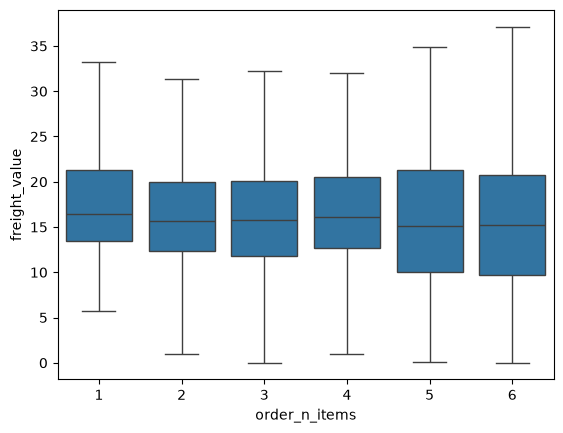

In [22]:
df3_6_boxplot = file_cleaned.loc[file_cleaned["order_n_items"] <= 6]
sns.boxplot(data=df3_6_boxplot,x="order_n_items",y="freight_value",showfliers=False)
plt.show()

In [23]:
actual = file_cleaned.groupby("order_id").size()
expected = file_cleaned.groupby("order_id")["order_n_items"].first()

check = pd.DataFrame({
    "actual": actual,
    "expected": expected
})

check_wrong = check.loc[check["actual"] != check["expected"]]

print("Số đơn không khớp:", len(check_wrong))
display(check_wrong)

Số đơn không khớp: 5


,actual,expected
order_id,,
09224348db675e0c2a00ebe2bd9599db,1,2
2480f727e869fdeb397244a21b721b67,1,2
2868cec2c0d3cc29873e13a46f55f532,1,2
80850824446cd379f755548b967c61b9,1,2
9d302458a5c2070516051da353068870,1,2


**Nhận xét:** order một item chiếm 85.856/108.937 item. Với nhóm 1–6 item, median nằm trong 15,10–16,47 BRL và các IQR chồng lấn nhiều; nhóm lớn có ít quan sát nên không có bằng chứng về xu hướng giảm đều. Boxplot chỉ hiển thị nhóm 1–6 và ẩn outlier, không xóa dữ liệu.

`order_item_id` là thứ tự item trong order; `order_n_items` là tổng số dòng của order trong bảng items gốc. Năm order có `order_n_items = 2` nhưng file cuối chỉ còn một dòng vì dòng còn lại bị loại trong Cleaning. Không sửa `order_n_items`, vì ép bằng số dòng còn lại sẽ làm mất ý nghĩa quy mô order ban đầu; chênh lệch chỉ ảnh hưởng 5/95.377 order.



### 3.7. Người bán và phí vận chuyển

**Mục tiêu:** Kiểm tra sự khác biệt về phí vận chuyển giữa các Seller.

**Phương pháp:**
- `groupby()` và `agg()`: So sánh phí vận chuyển giữa các Seller.
- Boxplot: Quan sát phân phối phí theo từng Seller.


In [24]:
seller_group = file_cleaned.groupby("seller_id")["freight_value"]
df3_7 = seller_group.agg(Count="count", Mean="mean", Median="median")
df3_7["Q1"] = seller_group.quantile(0.25)
df3_7["Q3"] = seller_group.quantile(0.75)
df3_7 = df3_7.sort_values(by="Count", ascending=False).head(10).reset_index()
display(df3_7.round(2))


,seller_id,Count,Mean,Median,Q1,Q3
0,6560211a19b47992c3666cc44a7e94c0,1991,13.70,14.10,7.78,16.12
1,4a3ca9315b744ce9f8e9374361493884,1947,17.61,15.70,12.93,18.53
2,1f50f920176fa81dab994f9023523100,1865,18.75,17.67,13.44,19.59
3,cc419e0650a3c5ba77189a1882b7556a,1704,14.45,14.34,9.41,16.39
4,da8622b14eb17ae2831f4ac5b9dab84a,1546,16.07,15.10,11.90,18.25
5,1025f0e2d44d7041d6cf58b6550e0bfa,1415,23.73,17.59,13.52,26.61
6,955fee9216a65b617aa5c0531780ce60,1370,18.01,15.78,12.86,20.84
7,7c67e1448b00f6e969d365cea6b010ab,1352,37.81,33.91,21.70,48.29
8,ea8482cd71df3c1969d7b9473ff13abc,1185,14.54,15.10,7.78,17.09
9,7a67c85e85bb2ce8582c35f2203ad736,1152,17.83,17.27,13.72,18.86


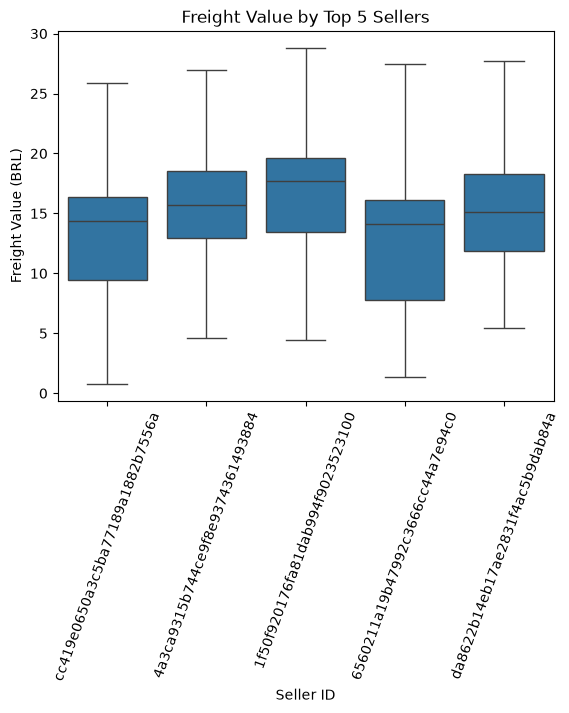

In [25]:
df3_7 = df3_7.head(5)
df3_7_boxplot = file_cleaned[file_cleaned["seller_id"].isin(df3_7["seller_id"])]
sns.boxplot(data=df3_7_boxplot, x="seller_id",y="freight_value",showfliers=False)
plt.xticks(rotation=70)
plt.title("Freight Value by Top 5 Sellers")
plt.xlabel("Seller ID")
plt.ylabel("Freight Value (BRL)")
plt.show()

Năm seller có nhiều item nhất đều có cỡ mẫu lớn, từ 1.546 đến 1.991 item. Median freight nằm trong 14,10–17,67 BRL; các IQR chồng lấn đáng kể, dù seller `656021...` có Q1 thấp hơn và khoảng IQR rộng hơn (7,78–16,12 BRL). Vì vậy có khác biệt mô tả giữa các seller nhưng không có hai phân phối tách rời hoàn toàn; loại sản phẩm, bang và khoảng cách có thể cùng tạo ra khác biệt. `seller_id` chỉ dùng để khảo sát, còn model dùng `seller_state` để tránh feature ID cardinality cao và khó áp dụng cho seller mới.



### 3.8. Danh mục sản phẩm và phí vận chuyển

**Mục tiêu:** Kiểm tra sự khác biệt về phí vận chuyển giữa các danh mục sản phẩm (`category`).

**Phương pháp:**
- `groupby()` và `agg()`: Thống kê số item, Mean và Median theo danh mục.
- Boxplot: So sánh phân phối phí giữa các danh mục phổ biến.


In [26]:
category_group = file_cleaned.groupby("category")["freight_value"]
df3_8 = category_group.agg(Count="count", Mean="mean", Median="median")
df3_8["Q1"] = category_group.quantile(0.25)
df3_8["Q3"] = category_group.quantile(0.75)
df3_8 = df3_8.sort_values(by="Count", ascending=False).head(10).reset_index()
display(df3_8.round(2))


,category,Count,Mean,Median,Q1,Q3
0,bed_bath_table,10901,18.43,16.19,13.29,19.72
1,health_beauty,9394,18.92,15.79,11.98,19.80
2,sports_leisure,8398,19.36,16.25,13.39,20.72
3,furniture_decor,7979,20.89,16.43,13.08,22.20
4,computers_accessories,7611,18.83,15.98,13.11,20.29
5,housewares,6765,21.02,16.76,13.01,22.66
6,watches_gifts,5621,17.37,16.01,13.05,19.22
7,telephony,4394,15.64,15.10,11.02,18.23
8,garden_tools,4196,22.94,17.67,13.78,26.25
9,auto,4121,21.86,17.60,13.74,23.49


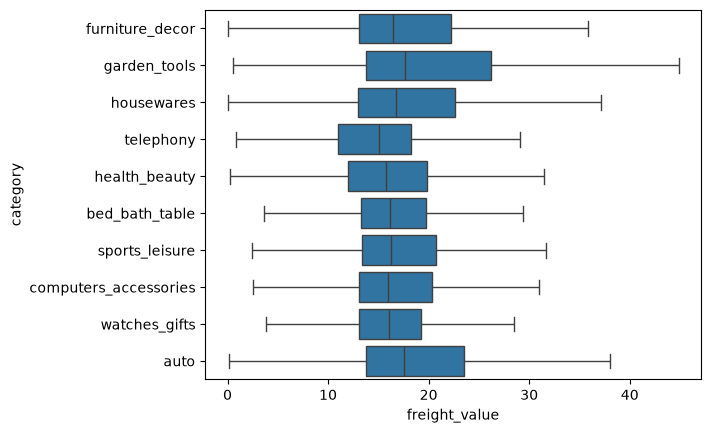

In [27]:
df3_8_boxplot = file_cleaned[file_cleaned["category"].isin(df3_8["category"])]
sns.boxplot(data=df3_8_boxplot, x="freight_value", y="category",showfliers=False)
plt.show()

Mười category phổ biến có từ 4.121 đến 10.901 item, nên so sánh không dựa trên nhóm quá nhỏ. Median chỉ dao động 15,10–17,67 BRL và phần lớn IQR chồng lấn; `garden_tools` có IQR cao/rộng hơn (13,78–26,25 BRL), còn `telephony` thấp hơn (11,02–18,23 BRL). Category vì vậy bổ sung thông tin về khác biệt sản phẩm, nhưng không tách riêng được ảnh hưởng của cân nặng, thể tích và khoảng cách. Model giữ category bằng one-hot và để validation đánh giá giá trị của nó trong tổ hợp chín feature.


### 3.9. Tổng hợp toàn bộ feature dùng trong Modeling

Heatmap Pearson đánh giá sáu biến số `price`, `weight_g`, `volume_cm3`, `distance_km`, `order_n_items`, `same_state` và target. Ba biến phân loại `category`, `customer_state`, `seller_state` được đánh giá bằng thống kê nhóm, không mã hóa thành số thứ tự và không tạo heatmap hàng trăm cột one-hot.


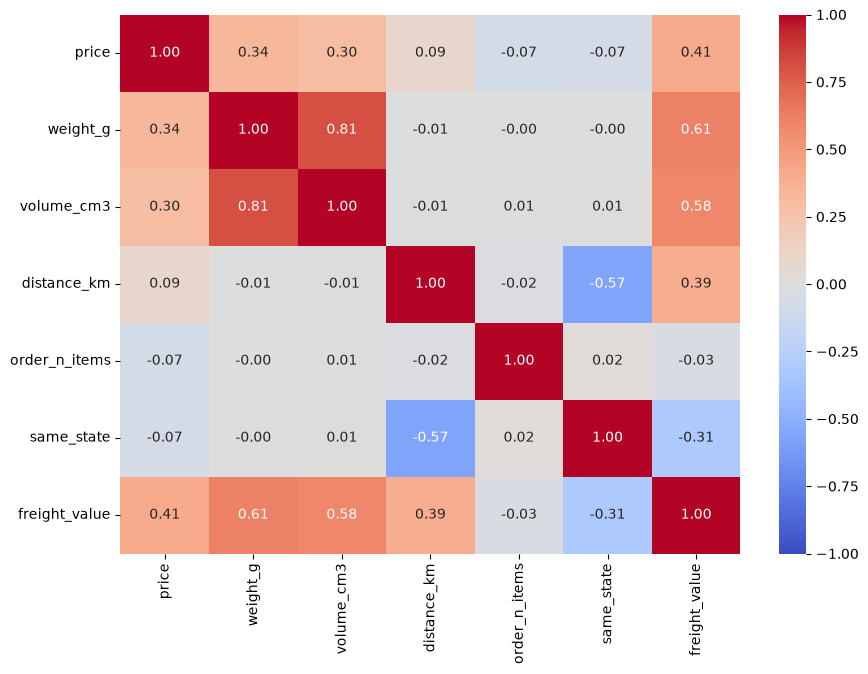

,Feature,Số nhóm,Nhóm có >=100 item,Median thấp nhất,Median cao nhất
0,category,74,54,12.94,41.55
1,customer_state,27,24,12.97,34.82
2,seller_state,22,13,15.38,33.08


In [28]:
cols = [
    'price', 'weight_g', 'volume_cm3', 'distance_km',
    'order_n_items', 'same_state', 'freight_value'
]
corr = file_cleaned[cols].corr(method='pearson')

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

category_stats = file_cleaned.groupby('category')['freight_value'].agg(Count='size', Median='median')
customer_stats = file_cleaned.groupby('customer_state')['freight_value'].agg(Count='size', Median='median')
seller_stats = file_cleaned.groupby('seller_state')['freight_value'].agg(Count='size', Median='median')

category_large = category_stats[category_stats['Count'] >= 100]
customer_large = customer_stats[customer_stats['Count'] >= 100]
seller_large = seller_stats[seller_stats['Count'] >= 100]

categorical_summary = pd.DataFrame({
    'Feature': ['category', 'customer_state', 'seller_state'],
    'Số nhóm': [len(category_stats), len(customer_stats), len(seller_stats)],
    'Nhóm có >=100 item': [len(category_large), len(customer_large), len(seller_large)],
    'Median thấp nhất': [category_large['Median'].min(), customer_large['Median'].min(), seller_large['Median'].min()],
    'Median cao nhất': [category_large['Median'].max(), customer_large['Median'].max(), seller_large['Median'].max()]
})
display(categorical_summary.round(2))


**Biến số:** theo heatmap làm tròn hai chữ số, `weight_g` (0,61) và `volume_cm3` (0,58) liên hệ dương mạnh nhất với freight; hai feature tương quan 0,81 nên có thông tin chồng lặp. `price` và `distance_km` lần lượt là 0,41 và 0,39. `same_state` tương quan -0,31 với freight và -0,57 với distance; `order_n_items` gần 0 (-0,03). Pearson chỉ đo quan hệ tuyến tính.

**Biến phân loại:** category và hai biến state được đánh giá bằng thống kê nhóm, không đưa vào Pearson bằng mã số. Trong các nhóm có ít nhất 100 item, median freight trải từ 12,94–41,55 BRL theo category, 12,97–34,82 theo bang khách và 15,38–33,08 theo bang người bán.

Heatmap và thống kê nhóm dùng toàn bộ dữ liệu chỉ để mô tả lịch sử. Danh sách chín feature đã được xác định trước từ Business Understanding và khả năng có dữ liệu tại checkout; kết quả EDA này không được dùng để thêm/bớt feature, chọn model hoặc tối ưu hyperparameter. Model vẫn được chọn bằng validation và test được giữ độc lập.


### 3.10. Tổng hợp mô tả chín feature

| Feature | Bằng chứng lịch sử |
|---|---|
| `weight_g` | Pearson 0,61; có đuôi cao |
| `volume_cm3` | Pearson 0,58; tương quan 0,81 với weight |
| `price` | Pearson 0,41, phân tán lớn |
| `distance_km` | Pearson 0,39; là khoảng cách Haversine |
| `order_n_items` | Pearson -0,03; các IQR nhóm chồng lấn |
| `same_state` | Pearson -0,31; median cùng bang 12,03 và khác bang 18,26 BRL |
| `category` | Median nhóm n≥100: 12,94–41,55 BRL |
| `customer_state` | Median nhóm n≥100: 12,97–34,82 BRL |
| `seller_state` | Median nhóm n≥100: 15,38–33,08 BRL |

Đây là kết quả mô tả trên toàn bộ dữ liệu, không phải bằng chứng để lựa chọn feature hoặc model. Không dùng `seller_id`, ID khác, payment, review hay thông tin giao hàng; việc chọn model chỉ dựa trên validation 07/2018, không dựa trên test.


## 4. Kiểm chứng các vấn đề còn tồn đọng ##

### 4.1. Kiểm chứng danh mục `unknown`

**Mục tiêu:** Đánh giá tính hợp lý của việc giữ các item thiếu thông tin danh mục sau Cleaning.

**Câu hỏi:**
- Có bao nhiêu item thuộc nhóm `unknown`?
- Nhóm này chiếm bao nhiêu phần trăm dữ liệu?
- Các item `unknown` còn đủ thông tin vật lý và vận chuyển không?
- Việc loại nhóm này có thể làm mất thông tin hữu ích không?


In [29]:
is_unknown = file_cleaned['category'] == 'unknown'

unknown_check = pd.DataFrame({
    'Số item': [is_unknown.sum()],
    'Tỷ lệ (%)': [is_unknown.mean() * 100],
    'Ô thiếu ở 8 feature còn lại': [file_cleaned.loc[is_unknown, [
        'price', 'weight_g', 'volume_cm3', 'distance_km',
        'order_n_items', 'same_state', 'customer_state', 'seller_state'
    ]].isna().sum().sum()]
})
display(unknown_check.round(2))

unknown_compare = file_cleaned.groupby(is_unknown)[
    ['freight_value', 'weight_g', 'volume_cm3', 'distance_km', 'price']
].median().round(2)
unknown_compare.index = ['Có category', 'Unknown']
display(unknown_compare)


,Số item,Tỷ lệ (%),Ô thiếu ở 8 feature còn lại
0,1510,1.39,0


,freight_value,weight_g,volume_cm3,distance_km,price
Có category,16.32,700.0,6555.0,431.8,74.90
Unknown,15.24,400.0,3600.0,404.7,75.77


Kết quả trực tiếp xác nhận 1.510 item `unknown` (1,39%) và không thiếu ô nào trong tám feature còn lại. So với nhóm có category, nhóm unknown có median freight thấp hơn nhẹ (15,24 so với 16,32 BRL), đồng thời nhẹ và nhỏ hơn theo median (400 so với 700 g; 3.600 so với 6.555 cm³). Đây là category gốc bị thiếu; hai mã thiếu bản dịch đã được Cleaning giữ bằng mã gốc nên không bị đánh đồng với `unknown`.

Không có bằng chứng nhóm này là dữ liệu sai hoặc thiếu toàn bộ thông tin dự đoán, nên loại sẽ làm mất 1.510 item có ích. Modeling xử lý `unknown` như một mức category riêng bằng one-hot; giới hạn là model không biết loại sản phẩm thật bên dưới nhãn này.


### 4.2. Kiểm chứng `freight_value = 0`

Clean CSV không còn freight bằng 0, nên phần này đọc trực tiếp các bảng raw và áp dụng tuần tự các điều kiện đã chạy ở Cleaning trước bước lọc target. Cleaning Cell 66 được dùng để đối chiếu thống kê khoảng cách; Cell 68 là bước loại freight bằng 0.

In [30]:
raw_items_4 = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
raw_orders_4 = pd.read_csv("../data/raw/olist_orders_dataset.csv")
raw_products_4 = pd.read_csv("../data/raw/olist_products_dataset.csv")
raw_customers_4 = pd.read_csv("../data/raw/olist_customers_dataset.csv")
raw_sellers_4 = pd.read_csv("../data/raw/olist_sellers_dataset.csv")
raw_geo_4 = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")

zero_4 = raw_items_4[raw_items_4["freight_value"] == 0].copy()
zero_4 = (zero_4
    .merge(raw_orders_4[["order_id", "customer_id", "order_status", "order_purchase_timestamp"]], on="order_id")
    .merge(raw_products_4[["product_id", "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]], on="product_id")
    .merge(raw_customers_4[["customer_id", "customer_zip_code_prefix"]], on="customer_id")
    .merge(raw_sellers_4[["seller_id", "seller_zip_code_prefix"]], on="seller_id"))

geo_ok_4 = raw_geo_4[
    raw_geo_4["geolocation_lat"].between(-34, 5.3) &
    raw_geo_4["geolocation_lng"].between(-74, -28)
]
valid_zip_4 = geo_ok_4["geolocation_zip_code_prefix"].unique()

zero_4["coordinate_ok"] = (
    zero_4["customer_zip_code_prefix"].isin(valid_zip_4) &
    zero_4["seller_zip_code_prefix"].isin(valid_zip_4)
)
physical_cols_4 = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
zero_4["physical_ok"] = zero_4[physical_cols_4].notna().all(axis=1)
zero_4["time_ok"] = pd.to_datetime(zero_4["order_purchase_timestamp"]).between("2017-01-01", "2018-08-31 23:59:59")

zero_steps_4 = pd.Series({
    "Items raw freight = 0": len(zero_4),
    "Sau kiểm tra tọa độ": zero_4["coordinate_ok"].sum(),
    "Sau kiểm tra vật lý": (zero_4["coordinate_ok"] & zero_4["physical_ok"]).sum(),
    "Sau khi giữ delivered": (zero_4["coordinate_ok"] & zero_4["physical_ok"] & zero_4["order_status"].eq("delivered")).sum(),
    "Sau phạm vi thời gian": (zero_4["coordinate_ok"] & zero_4["physical_ok"] & zero_4["order_status"].eq("delivered") & zero_4["time_ok"]).sum(),
    "Trước bước lọc freight = 0": (zero_4["coordinate_ok"] & zero_4["physical_ok"] & zero_4["order_status"].eq("delivered") & zero_4["time_ok"] & zero_4["product_weight_g"].gt(0)).sum()
})
display(zero_steps_4.to_frame("Số item"))

zero_4["Lý do bị loại trước bước target"] = ""
zero_4.loc[~zero_4["coordinate_ok"], "Lý do bị loại trước bước target"] = "Thiếu tọa độ hợp lệ"
zero_4.loc[zero_4["coordinate_ok"] & ~zero_4["order_status"].eq("delivered"), "Lý do bị loại trước bước target"] = "Order chưa delivered"
display(zero_4[zero_4["Lý do bị loại trước bước target"] != ""][[
    "order_id", "order_item_id", "order_status", "Lý do bị loại trước bước target"
]])

,Số item
Items raw freight = 0,383
Sau kiểm tra tọa độ,382
Sau kiểm tra vật lý,382
Sau khi giữ delivered,380
Sau phạm vi thời gian,380
Trước bước lọc freight = 0,380


,order_id,order_item_id,order_status,Lý do bị loại trước bước target
43,1c57efb710fa0df4433b44a5c39e4b6e,1,shipped,Order chưa delivered
158,6fbd65f0ae756ffd1692f812a7b411a4,1,shipped,Order chưa delivered
310,d0bec96aad189992b278688279ba1511,1,delivered,Thiếu tọa độ hợp lệ


Dữ liệu raw có 383 item freight bằng 0. Một item bị loại do thiếu tọa độ hợp lệ và hai item thuộc order `shipped`, nên còn đúng 380 item trước bước lọc target. Cleaning Cell 66 cho thấy nhóm zero có distance median 505,6 km, không thấp hơn nhóm dương 431,3 km; khoảng cách vì vậy không giải thích được giá trị 0.

Bằng chứng không chứng minh các item này sai, cũng không cho biết đó là miễn phí, khuyến mãi hay cách ghi nhận khác. Nhóm loại chúng để xác định một target freight dương nhất quán, nhưng đây là giới hạn sản phẩm: tại checkout chưa biết trước trường hợp nào sẽ có freight bằng 0, nên công cụ không áp dụng cho các trường hợp đó.

### 4.3. Kiểm chứng `order_item_id` và `order_n_items`

`order_item_id` là thứ tự item trong order. Cleaning Cell 73 tạo `order_n_items` bằng số dòng của mỗi `order_id` trong bảng items gốc, trước khi loại dòng. Code dưới đây đối chiếu năm order không khớp với raw để xác định item nào đã mất và lý do.

In [31]:
mismatch_orders_4 = check_wrong.index

excluded_items_4 = raw_items_4[raw_items_4["order_id"].isin(mismatch_orders_4)].merge(
    file_cleaned[["order_id", "order_item_id"]],
    on=["order_id", "order_item_id"], how="left", indicator=True
)
excluded_items_4 = excluded_items_4[excluded_items_4["_merge"] == "left_only"].drop(columns="_merge")
excluded_items_4 = (excluded_items_4
    .merge(raw_orders_4[["order_id", "customer_id"]], on="order_id")
    .merge(raw_customers_4[["customer_id", "customer_zip_code_prefix"]], on="customer_id")
    .merge(raw_sellers_4[["seller_id", "seller_zip_code_prefix"]], on="seller_id"))

excluded_items_4["coordinate_ok"] = (
    excluded_items_4["customer_zip_code_prefix"].isin(valid_zip_4) &
    excluded_items_4["seller_zip_code_prefix"].isin(valid_zip_4)
)
excluded_items_4["Lý do"] = ""
excluded_items_4.loc[~excluded_items_4["coordinate_ok"], "Lý do"] = "Thiếu tọa độ hợp lệ"
excluded_items_4.loc[excluded_items_4["freight_value"] == 0, "Lý do"] = "freight_value = 0"

display(excluded_items_4[[
    "order_id", "order_item_id", "freight_value", "coordinate_ok", "Lý do"
]].sort_values("order_id"))

,order_id,order_item_id,freight_value,coordinate_ok,Lý do
0,09224348db675e0c2a00ebe2bd9599db,2,4.09,False,Thiếu tọa độ hợp lệ
1,2480f727e869fdeb397244a21b721b67,1,15.56,False,Thiếu tọa độ hợp lệ
2,2868cec2c0d3cc29873e13a46f55f532,1,11.53,False,Thiếu tọa độ hợp lệ
3,80850824446cd379f755548b967c61b9,1,0.00,True,freight_value = 0
4,9d302458a5c2070516051da353068870,2,42.11,False,Thiếu tọa độ hợp lệ


Mỗi order chênh đúng một item: bốn item bị loại vì thiếu tọa độ hợp lệ và một item vì `freight_value = 0`. Giữ `order_n_items` theo order gốc là hợp lý vì feature vẫn mô tả quy mô giỏ hàng tại checkout; ép bằng số dòng sau Cleaning sẽ biến nó thành kết quả của quy trình lọc. Khác biệt chỉ xuất hiện ở 5/95.377 order về số lượng bản ghi, nhưng chưa có kiểm định riêng để khẳng định tác động dự đoán bằng 0.

### 4.4. Kiểm chứng outlier

EDA Cell 19 dùng cùng file cuối và cùng công thức IQR với Cleaning. Rào dưới là 0,975 BRL và rào trên là 33,255 BRL: 133 item nằm dưới rào dưới, 11.216 item nằm trên rào trên, tổng 11.349 item (10,42%). Cleaning Cell 88 chỉ tạo điều kiện vượt rào trên nên báo cáo 11.216 item; khác biệt 133 item đến từ phạm vi đếm, không phải khác dataset hay khác ngưỡng.

Các phân tích weight, volume và distance cho thấy vùng phí cao thường đi cùng hàng nặng/cồng kềnh hoặc tuyến xa, nhưng không có bảng cước độc lập để xác minh từng điểm; vì vậy vượt IQR không đủ chứng minh lỗi và target không bị xóa hay biến đổi. Giữ đuôi phân phối làm bài toán khó hơn: trên test, nhóm freight trên P90 có MAE 19,74 và bias -18,17 BRL. P90 được tạo bằng freight thực tế chỉ để hậu kiểm test, không phải điều kiện cảnh báo có thể biết trước cho order mới.


### 4.5. Những hạn chế còn có ý nghĩa

Cleaning đã xử lý missing và duplicate trong bảng cuối, nhưng không thể bổ sung thông tin không có trong nguồn. Tọa độ là trung vị ZIP và Haversine không phải quãng đường đường bộ; hai category thiếu bản dịch chỉ giữ mã gốc; `unknown` vẫn che giấu loại sản phẩm thật. Freight ở grain item không phải tổng freight của order, còn dữ liệu thiếu hãng vận chuyển, loại dịch vụ, biểu phí và khuyến mãi. Các quyết định chỉ giữ delivered, 01/2017–08/2018 và freight dương vì vậy giới hạn phạm vi áp dụng, thay vì giải quyết hoàn toàn bài toán tính phí chính thức.

### 4.6. Tổng hợp quyết định

| Vấn đề | Bằng chứng | Quyết định | Giới hạn/Ảnh hưởng |
|---|---|---|---|
| Category `unknown` | 1.510 item, 1,39%; đủ tám feature khác | Giữ và one-hot riêng | Không biết category thật |
| Freight bằng 0 | 383 raw; còn 380 sau 1 thiếu tọa độ và 2 order chưa delivered | Loại khỏi target nghiên cứu | Sản phẩm chỉ dự đoán freight dương |
| `order_n_items` lệch | 4 item thiếu tọa độ, 1 item freight 0 | Giữ số item của order gốc | Chưa kiểm định riêng tác động ở 5 order |
| Outlier IQR | 133 dưới + 11.216 trên = 11.349 item; chưa xác minh từng điểm là lỗi | Giữ nguyên | P90 có MAE 19,74 và bias -18,17 BRL |
| Địa lý đại diện | Tọa độ ZIP trung vị, Haversine | Chấp nhận có giới hạn | Không phải quãng đường thực tế |
| Thiếu thông tin tính cước | Không có carrier, dịch vụ, biểu phí/khuyến mãi | Ghi nhận, không suy đoán | Chỉ là mức tham khảo lịch sử |

## 5. Kết luận EDA và đề xuất Modeling

Sau khi hoàn tất các phân tích và kiểm chứng vấn đề dữ liệu, các đặc điểm vật lý tạo tín hiệu nổi bật nhất: weight và volume đều liên hệ dương với freight, nhưng tương quan 0,81 giữa chúng cho thấy một phần thông tin bị chồng lặp. Nhóm địa lý bổ sung một khía cạnh khác: distance, same state và hai biến state mô tả nơi gửi–nhận, song khoảng cách chỉ là Haversine và chênh lệch giữa các bang còn chịu ảnh hưởng của cơ cấu sản phẩm. Price, category và order items tiếp tục bổ sung thông tin về sản phẩm/đơn hàng, dù `order_n_items` gần như không có quan hệ tuyến tính và các nhóm category còn chồng lấn.

Bức tranh chung là không feature nào giải thích hoàn toàn freight. Scatterplot đều có độ phân tán, các boxplot có chồng lấn và target lệch phải với một vùng phí cao khó dự đoán. Vì vậy nhóm đề xuất **Linear Regression** làm mô hình đơn giản để kiểm tra quan hệ tuyến tính kết hợp nhiều feature, và **Random Forest** để thử các quan hệ phi tuyến cùng tương tác mà đường thẳng khó biểu diễn. Random Forest đổi lại khó giải thích từng dự đoán hơn.

Danh sách chín feature được xác định từ yêu cầu bài toán và khả năng có dữ liệu tại checkout, không được tối ưu từ EDA toàn bộ lịch sử. EDA chỉ hình thành giả thuyết về hai phương pháp. Phần Modeling tiếp theo sẽ dùng validation 07/2018 để xác định model tốt hơn, còn test 08/2018 được giữ độc lập để đánh giá cuối.